[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Elheims/scikit-learn-cookbook/blob/main/13.%20Deploying%20scikit-learn%20Models%20in%20Production/ch13_deploying_models.ipynb)

# Chapter 13: Deploying scikit-learn Models in Production

**Book:** *scikit-learn Cookbook, Third Edition* (John Sukup, Packt) — Chapter 13, pp. 354–371

**What you will learn in this chapter:**
- What deployment involves: packaging a trained model as an artifact, serving it, and keeping it correct as data change
- How to persist models with `pickle` and `joblib`, and the real security and versioning risks of doing so
- How to scale training and prediction (`n_jobs`, batching, incremental learning) — and when parallelism *hurts*
- How to monitor a deployed model for drift and decide when to retrain
- How to manage a model's life cycle: versioning, metadata, validation snapshots, rollback
- How to build a deployment gate (CI/CD) that really protects production
- Practical exercises: saving/reloading a pipeline, monitoring accuracy over time, automated deployment checks

## Chapter summary

| Section | Core idea | Key API |
|---|---|---|
| Overview of deployment | Persist, load, serve (batch is cheaper than one-by-one) | `joblib.dump` / `load` |
| Serialization | Models are saved as bytes; unpickling runs code; versions must match | `pickle`, `joblib` |
| Scaling | Parallelism and batching trade latency against throughput | `n_jobs`, `cross_val_score`, `partial_fit` |
| Monitoring | Track batch accuracy and input drift; retrain on degradation | `SGDClassifier.partial_fit`, `ks_2samp` |
| Life cycle | Versioned artifact + metadata + validation snapshot | `json`, `joblib` |
| Deployment pipelines | One artifact (`Pipeline`), a validation gate before promotion | `Pipeline`, `accuracy_score` |
| Practical exercises | Reload a pipeline, monitor over time, gate a deployment | — |

**How this notebook is organised.** Each section has a summary, the book's code reproduced and executed, a verification against the numbers and figures printed in the book, and a *Theory* cell.
Cells marked **Extension** are not in the book's code. Places where the book's text or code is inaccurate or incomplete are flagged with **Book correction** (collected again at the end).
**Files:** the book writes `model.joblib`, `rf.pkl`, … into the current directory. This notebook switches to a temporary folder first, so the repository stays clean.

In [1]:
import os, tempfile, time, json, pickle, hashlib, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

WORKDIR = Path(tempfile.mkdtemp(prefix="ch13_"))
os.chdir(WORKDIR)                                   # every artifact below is written here, not into the repository
print("scikit-learn version:", sklearn.__version__)
print("NumPy version       :", np.__version__)
print("artifacts folder    :", WORKDIR)
print("CPU cores           :", os.cpu_count())

scikit-learn version: 1.9.1
NumPy version       : 2.5.3
artifacts folder    : C:\Users\tatak\AppData\Local\Temp\ch13_fyxujq2c
CPU cores           : 16


## 1. Overview of model deployment

**Summary.** Deploying a model means moving it from the development environment to production so that users or systems can obtain its predictions. It involves preparing a reliable **artifact** (the model plus its metadata), serving it with suitable latency and throughput, and making sure it keeps performing as data evolve. The book walks through packaging, exposing and verifying a trained model.

### Getting ready

In [2]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_classification
from joblib import dump, load

In [3]:
X, y = make_classification(
    n_samples=1000, n_features=20, random_state=2024)
clf = LogisticRegression()
clf.fit(X, y)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

### How to do it…
Persist the model to disk and simulate loading it "in a new environment":

In [4]:
dump(clf, "model.joblib")

['model.joblib']

In [5]:
clf_loaded = load("model.joblib")

In [6]:
np.random.seed(2024)                          # added: the book's call is unseeded, so its printed class varies from run to run
incoming = np.random.rand(1, 20)
print(clf_loaded.predict(incoming))

[1]


**Verification against the book:** the three steps work as described and the model predicts a class for the incoming row ✔. (The book's `incoming` is random noise with no seed, so the printed class itself carries no meaning; a seed was added only for reproducibility.)

### How it works…
The book recommends `joblib` to persist scikit-learn models ("it handles NumPy arrays efficiently compared to standard pickle"), loaded by the same library versions; afterwards "the model behaves identically to the original". The book also says "with only four lines of code, we are able to save, load, and test an ML model using Python's **built-in** functions" — `joblib` is a separate package (a dependency of scikit-learn), not part of Python's standard library.

**Extension 1 — "behaves identically": verify it,** including the probabilities, the parameters and the artifact size:

In [7]:
print("same predictions     :", np.array_equal(clf.predict(X), clf_loaded.predict(X)))
print("same probabilities   :", np.array_equal(clf.predict_proba(X), clf_loaded.predict_proba(X)))
print("same coefficients    :", np.array_equal(clf.coef_, clf_loaded.coef_), "| same hyper-parameters:", clf.get_params() == clf_loaded.get_params())
print("artifact size        :", os.path.getsize("model.joblib"), "bytes (20 coefficients + intercept + metadata)")

same predictions     : True
same probabilities   : True
same coefficients    : True | same hyper-parameters: True
artifact size        : 1007 bytes (20 coefficients + intercept + metadata)


**Extension 2 — a minimal "prediction endpoint".** What a REST service does with the loaded model, simulated as a function that takes a JSON request: it must validate the input, because the model will not accept a wrong number of features:

In [8]:
def predict_endpoint(payload: str, model=clf_loaded) -> str:
    data = json.loads(payload)
    x = np.asarray(data["features"], dtype=float)
    x = x.reshape(1, -1) if x.ndim == 1 else x
    if x.shape[1] != model.n_features_in_:
        return json.dumps({"error": f"expected {model.n_features_in_} features, got {x.shape[1]}"})
    return json.dumps({"prediction": model.predict(x).tolist(), "probability_of_class_1": model.predict_proba(x)[:, 1].round(4).tolist()})

print("valid request  ->", predict_endpoint(json.dumps({"features": X[0].round(3).tolist()})))
print("two rows       ->", predict_endpoint(json.dumps({"features": X[:2].round(3).tolist()})))
print("wrong width    ->", predict_endpoint(json.dumps({"features": [0.1, 0.2, 0.3]})))

valid request  -> {"prediction": [1], "probability_of_class_1": [0.8845]}
two rows       -> {"prediction": [1, 1], "probability_of_class_1": [0.8845, 0.549]}
wrong width    -> {"error": "expected 20 features, got 3"}


### There's more…
Deployment can mean REST APIs, batch pipelines or serverless functions. The book notes that **bulk prediction** is far more efficient than one-at-a-time calls "due to linear algebra optimizations". The hands-on exercise asks to compare latency for single versus batch requests — measured here for the logistic regression and for a random forest:

In [9]:
from sklearn.ensemble import RandomForestClassifier

rng = np.random.default_rng(0)
Xq = rng.normal(size=(1000, 20))
rf_demo = RandomForestClassifier(n_estimators=100, n_jobs=1, random_state=2024).fit(X, y)

def per_sample_us(model, n=300):
    singles = []
    for i in range(n):
        t0 = time.perf_counter(); model.predict(Xq[i:i + 1]); singles.append(time.perf_counter() - t0)
    t0 = time.perf_counter(); model.predict(Xq); batch = time.perf_counter() - t0
    return np.median(singles) * 1e6, batch / len(Xq) * 1e6

rows = {}
for name, m in [("LogisticRegression", clf_loaded), ("RandomForest (100 trees, n_jobs=1)", rf_demo)]:
    s, b = per_sample_us(m)
    rows[name] = {"one-by-one (µs / sample)": s, "one batch of 1,000 (µs / sample)": b, "speed-up": s / b}
display(pd.DataFrame(rows).T.round(1))

,one-by-one (µs / sample),"one batch of 1,000 (µs / sample)",speed-up
LogisticRegression,216.2,0.3,708.2
"RandomForest (100 trees, n_jobs=1)",11869.6,17.9,663.4


Predicting **one row at a time** costs ≈ 220 µs per row for the logistic regression and ≈ 12 ms for the 100-tree forest, whereas one **batch of 1,000 rows** costs 0.3 µs and 18 µs per row — roughly **700×** cheaper per sample in both cases. The book's statement is right; its explanation ("linear algebra optimizations") is only part of the story, since most of the single-row cost is fixed per-call overhead (Python call, input validation and, for the forest, the pass over every tree) — which is why online services micro-batch their requests.

### Theory — what "deployment" means
* **Artifact:** the fitted estimator (ideally the whole `Pipeline`) plus metadata. Training happens once per cycle; prediction is repeated millions of times, so the two are decoupled by a saved artifact.
* **Serving patterns:** *online* (REST/gRPC: low latency per request), *batch* (scheduled scoring of a table: high throughput), *edge/serverless*. Per-request overhead (Python call, input validation, parsing) dominates for single rows — hence micro-batching.
* **Contract:** a deployed model expects the same features, in the same order and with the same preprocessing as in training — validate inputs (above), and ship preprocessing *inside* the artifact (Section 6).
* **Beyond the model:** latency/throughput budgets, monitoring, rollback and retraining (CI/CD/**CT**) are what make up most of production ML (the book's own remark).

### Hands-on workflow (book)
Train and export a logistic regression with `joblib`, simulate a client that loads the model and requests predictions, measure prediction time for a single instance and for a batch, and examine throughput and latency — as above.

## 2. Serialization and persistence techniques

**Summary.** Training happens once per CI/CD/CT cycle, prediction repeatedly, so models are **serialised** — turned into a byte stream that can be stored and moved. The book demonstrates `pickle` and `joblib`, discusses security and versioning, and mentions non-Python formats (ONNX, PMML) for Python-free environments.

### Getting ready

In [10]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification
import pickle
from joblib import dump, load

In [11]:
X, y = make_classification(
    n_samples=500, n_features=15, random_state=2024)
rf = RandomForestClassifier(
    n_estimators=10, random_state=2024)
rf.fit(X, y)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",2024
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootst

### How to do it…

In [12]:
with open("rf.pkl", "wb") as f:
    pickle.dump(rf, f)

In [13]:
dump(rf, "rf.joblib")

['rf.joblib']

In [14]:
with open("rf.pkl", "rb") as f:
    rf1 = pickle.load(f)

In [15]:
rf2 = load("rf.joblib")

In [16]:
assert np.array_equal(rf.predict(X[:5]),
                      rf1.predict(X[:5]))
assert np.array_equal(rf.predict(X[:5]),
                      rf2.predict(X[:5]))
print("both assertions passed | file sizes: rf.pkl =", os.path.getsize("rf.pkl"), "bytes, rf.joblib =", os.path.getsize("rf.joblib"), "bytes")

both assertions passed | file sizes: rf.pkl = 58033 bytes, rf.joblib = 59209 bytes


**Verification against the book:** both loaded models reproduce the original predictions (the assertions pass) ✔.

### How it works…
The book says `pickle` "can struggle with large NumPy arrays inside estimators" and that `joblib` is "optimized for such cases and is the recommended method". It also warns that unpickling requires **trust** and that models saved with one scikit-learn version "may break" in another, and suggests ONNX/PMML for non-Python contexts. Each claim can be tested.

**Extension 1 — is `joblib` faster or smaller than `pickle`?** A larger forest (100 trees on 20,000 samples) and a 200 MB array:

In [17]:
Xb, yb = make_classification(n_samples=20000, n_features=50, random_state=0)
rf_big = RandomForestClassifier(n_estimators=100, random_state=0).fit(Xb, yb)

def timed(fn):
    t0 = time.perf_counter(); out = fn(); return out, time.perf_counter() - t0

rows = {}
_, t_dump = timed(lambda: pickle.dump(rf_big, open("rf_big.pkl", "wb")))
_, t_load = timed(lambda: pickle.load(open("rf_big.pkl", "rb")))
rows["pickle"] = {"size (MB)": os.path.getsize("rf_big.pkl") / 1e6, "dump (s)": t_dump, "load (s)": t_load}
_, t_dump = timed(lambda: dump(rf_big, "rf_big.joblib"))
_, t_load = timed(lambda: load("rf_big.joblib"))
rows["joblib"] = {"size (MB)": os.path.getsize("rf_big.joblib") / 1e6, "dump (s)": t_dump, "load (s)": t_load}
_, t_dump = timed(lambda: dump(rf_big, "rf_big_c.joblib", compress=3))
_, t_load = timed(lambda: load("rf_big_c.joblib"))
rows["joblib, compress=3"] = {"size (MB)": os.path.getsize("rf_big_c.joblib") / 1e6, "dump (s)": t_dump, "load (s)": t_load}
display(pd.DataFrame(rows).T.round(3))

big = np.random.default_rng(0).random((5000, 5000))                        # a 200 MB array
_, t_pk = timed(lambda: pickle.dump(big, open("big.pkl", "wb")))
_, t_jl = timed(lambda: dump(big, "big.joblib"))
mm, t_mm = timed(lambda: load("big.joblib", mmap_mode="r"))
print(f"200 MB array: pickle dump {t_pk:.2f} s | joblib dump {t_jl:.2f} s | joblib load with mmap_mode='r' {t_mm * 1000:.0f} ms (returns a {type(mm).__name__}, data stay on disk until used)")

,size (MB),dump (s),load (s)
pickle,20.509,0.023,0.057
joblib,20.518,0.064,0.072
"joblib, compress=3",4.565,0.310,0.130


200 MB array: pickle dump 0.18 s | joblib dump 0.10 s | joblib load with mmap_mode='r' 11 ms (returns a memmap, data stay on disk until used)


For a 20.5 MB forest, `pickle` and `joblib` produce files of the **same size** (20.5 MB) and run at similar speed (dump 0.02–0.03 s vs 0.06 s, load 0.06 s vs 0.07 s); for a 200 MB array `pickle` dumps in ≈ 0.18 s against 0.10 s for `joblib`. Since Python 3.8 (pickle protocol 5) plain `pickle` handles NumPy arrays efficiently, so the book's "pickle struggles with large NumPy arrays" does not hold today.
What `joblib` genuinely adds: **compression** (4.6 MB with `compress=3`, at the price of a ≈ 5× slower dump) and **memory-mapping** (the 200 MB array is "loaded" in about 10 ms with `mmap_mode='r'`, useful when several worker processes share one model).

**Extension 2 — "never use untrusted files": what that means.** Unpickling can execute *arbitrary code*: a pickle is a program for the unpickler. A harmless demonstration (the payload only prints a message):

In [18]:
class Payload:
    def __reduce__(self):
        return (print, ("*** this code ran just by loading the file ***",))

blob = pickle.dumps(Payload())
print("loading the bytes now ...")
pickle.loads(blob)                                    # joblib.load uses the same mechanism

loading the bytes now ...
*** this code ran just by loading the file ***


A malicious file could run any command instead of `print`. Load model files only from sources you control, verify their integrity (a checksum, below), or use formats that cannot execute code (e.g. `skops` for scikit-learn models, or ONNX).

**Extension 3 — version compatibility.** scikit-learn stores its version inside the saved estimator and warns when the loading version differs. Simulating an artifact created by scikit-learn 1.3.2 (by temporarily patching the version string used when pickling — a simulation, since only 1.9.1 is installed here):

In [19]:
import sklearn.base

print("version stored in a freshly pickled estimator:", rf.__getstate__()["_sklearn_version"])
real_version = sklearn.base.__version__
sklearn.base.__version__ = "1.3.2"                    # pretend the model was trained with scikit-learn 1.3.2
dump(rf, "rf_from_1_3_2.joblib")
sklearn.base.__version__ = real_version

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    old = load("rf_from_1_3_2.joblib")
from collections import Counter
by_class = Counter(str(w.message).split("estimator ")[1].split(" from")[0] for w in caught)
print(f"{len(caught)} warnings of type {caught[0].category.__name__}, one per saved estimator: {dict(by_class)}")
print("message:", str(caught[0].message))
print("predictions still equal in this case:", np.array_equal(old.predict(X), rf.predict(X)), "(not guaranteed across real version changes: internal attributes can change)")

version stored in a freshly pickled estimator: 1.9.1
12 warnings of type InconsistentVersionWarning, one per saved estimator: {'DecisionTreeClassifier': 11, 'RandomForestClassifier': 1}
message: Trying to unpickle estimator DecisionTreeClassifier from version 1.3.2 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
predictions still equal in this case: True (not guaranteed across real version changes: internal attributes can change)


**Extension 4 — integrity.** A SHA-256 checksum stored next to the artifact (Section 5) detects corruption or tampering before the file is ever unpickled:

In [20]:
sha = hashlib.sha256(Path("rf.joblib").read_bytes()).hexdigest()
print("sha256(rf.joblib) =", sha)
tampered = bytearray(Path("rf.joblib").read_bytes()); tampered[-1] ^= 0xFF
print("checksum after changing one byte differs:", hashlib.sha256(bytes(tampered)).hexdigest() != sha)

sha256(rf.joblib) = ae5afb5548f2e09bb4e8e6fd4d07070ebe505a344d960eec15e786ffcff1b7b1
checksum after changing one byte differs: True


### There's more…
Model persistence best practices include snapshotting the code, library versions, training data and validation outputs (Section 5). `cloudpickle` can serialise objects that `pickle`/`joblib` cannot (custom or dynamically generated estimators, lambdas). The book's exercise suggests exporting to ONNX with `skl2onnx` — an optional package not installed here and not run.

> **Book correction (a wording slip).** The recipe says it will "convert our models into Python arrays"; serialisation produces a **byte stream**, as the book itself says a few paragraphs later.

### Theory — serialization
* **What is saved:** the fitted estimator object — hyper-parameters *and* learned attributes (`coef_`, trees, …) — not the code. Loading needs the same class definitions (same library version, same custom code importable under the same name).
* **pickle vs joblib:** both use Python's pickle protocol; `joblib` adds efficient handling of large NumPy arrays (compression, memory-mapping). In current Python (pickle protocol 5) plain `pickle` is also efficient for arrays — measured above.
* **Risks:** (1) *security* — unpickling runs code; (2) *compatibility* — different scikit-learn/NumPy/Python versions may fail or silently differ; (3) *reproducibility* — nothing is recorded about how the model was made.
* **Mitigations:** pin the environment (requirements, container), store the version and a checksum with the artifact, keep a validation snapshot to compare predictions after any upgrade, prefer safe formats across trust boundaries.

### Hands-on workflow (book)
Train a classifier, save copies as `.pkl` and `.joblib`, load them in separate Python sessions, verify predictive consistency, and explore ONNX export if desired — the in-process version is above.

## 3. Scaling models for production

**Summary.** Real deployments face large datasets, distributed infrastructure or heavy inference demand. The recipe explores `n_jobs`, joblib parallelism, external backends such as Dask and batch serving.

### Getting ready

In [21]:
import numpy as np
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
import time

In [22]:
X, y = make_classification(
    n_samples=2000, n_features=50, random_state=2024)
clf = RandomForestClassifier(
    n_estimators=100, n_jobs=-1, random_state=2024)
clf.fit(X, y)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",2024
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the tot

### How to do it…
(The book says "let's try predicting on a random batch size of **text** data" — the batch is numeric noise, not text.)

In [23]:
batch = np.random.rand(1000, 50)
start = time.time()
clf.predict(batch)
print("Time:", time.time() - start)

Time: 0.044342756271362305


In [24]:
scores = cross_val_score(
    RandomForestClassifier(n_estimators=50),
    X, y, cv=3, n_jobs=-1
)
print("CV Accuracy:", np.mean(scores))

CV Accuracy: 0.8725014369692031


In [25]:
# from dask.distributed import Client
# from dask_ml.model_selection import GridSearchCV as daskGSCV
print("Dask is optional and not used here (the book keeps these two lines commented out).")

Dask is optional and not used here (the book keeps these two lines commented out).


**Verification against the book:** the latency (a few tens of milliseconds for 1,000 rows) and a cross-validated accuracy ≈ 0.87 are as expected ✔ (neither is printed in the book; the CV forest has no `random_state`, so the second number varies slightly).

### How it works…
Many estimators accept `n_jobs` and parallelise through joblib; Dask can act as a distributed backend; batch serving gives much better throughput than single requests "due to lower overhead and better CPU utilization". The implicit message is "use `n_jobs=-1`". Whether that is right depends on the workload:

**Extension 1 — `n_jobs` for prediction.** Latency per request for one row and for batches of 1,000 and 100,000 rows with a 100-tree forest, with 1, 2 and all cores:

In [26]:
rng = np.random.default_rng(0)
rows = {}
for nj in [1, 2, -1]:
    m = RandomForestClassifier(n_estimators=100, n_jobs=nj, random_state=2024)
    t0 = time.perf_counter(); m.fit(X, y); fit_t = time.perf_counter() - t0
    one = rng.random((1, 50)); b1k = rng.random((1000, 50)); b100k = rng.random((100_000, 50))
    m.predict(b1k)                                                       # warm-up
    singles = []
    for _ in range(30):
        t0 = time.perf_counter(); m.predict(one); singles.append(time.perf_counter() - t0)
    t_one = np.median(singles)
    t0 = time.perf_counter(); m.predict(b1k); t_1k = time.perf_counter() - t0
    t0 = time.perf_counter(); m.predict(b100k); t_100k = time.perf_counter() - t0
    rows[f"n_jobs={nj}"] = {"fit (s)": fit_t, "1 row (ms)": t_one * 1000, "1,000 rows (ms)": t_1k * 1000, "100,000 rows (s)": t_100k}
display(pd.DataFrame(rows).T.round(3))

,fit (s),1 row (ms),"1,000 rows (ms)","100,000 rows (s)"
n_jobs=1,1.009,12.005,17.648,0.496
n_jobs=2,0.592,36.360,36.057,0.295
n_jobs=-1,0.252,39.076,42.532,0.131


**Parallelism is not free.** For a single request `n_jobs=1` takes ≈ 12 ms, whereas `n_jobs=2` or `-1` take ≈ 36–39 ms — about **3× slower**: starting and synchronising the thread pool costs more than the work. The same holds for the book's 1,000-row batch (18 ms vs 36–43 ms). Only for a large batch does it pay: 100,000 rows take 0.50 s with one core, 0.30 s with two and 0.13 s with all 16 (≈ 4× faster); fitting also speeds up 4× (1.0 s → 0.25 s).
The consequence: the book's latency cell (`n_jobs=-1`, 1,000 rows, ≈ 45 ms) is *slower* than the same forest would be with `n_jobs=1` (≈ 18 ms). Rule of thumb: `n_jobs=-1` for training and large-batch scoring; `n_jobs=1` for latency-critical single-row serving, scaling out with more service replicas instead.

**Extension 2 — `n_jobs` for cross-validation:** the folds are independent, so parallelism pays off when each fold is expensive:

In [27]:
rows = {}
for nj in [None, -1]:
    t0 = time.perf_counter()
    s = cross_val_score(RandomForestClassifier(n_estimators=300, random_state=0), X, y, cv=5, n_jobs=nj)
    rows[f"cross_val_score(n_jobs={nj})"] = {"seconds": time.perf_counter() - t0, "mean accuracy": s.mean()}
display(pd.DataFrame(rows).T.round(3))

,seconds,mean accuracy
cross_val_score(n_jobs=None),11.429,0.872
cross_val_score(n_jobs=-1),6.542,0.872


Five folds of a 300-tree forest take ≈ 11.5 s sequentially and ≈ 6.5 s with `n_jobs=-1` — 1.8×, far below the 5× the fold count would allow, because starting worker processes and copying the data have a cost and the number of folds caps the parallelism. The scores are identical (0.872): parallelism changes the time, not the result.

### There's more…
For data that arrive over time or do not fit in memory, `SGDClassifier` (and other estimators with `partial_fit`) learn incrementally — used in Section 4. Containerisation (Docker), autoscaling and GPU-backed serving are beyond the book's scope (and this notebook's).

### Theory — scaling
* **Throughput vs latency:** batching raises throughput (amortises per-call overhead) but adds waiting time; online services use *micro-batches*.
* **`n_jobs` parallelises over independent work units** (trees, folds, grid points) using processes/threads; it has a fixed start-up and synchronisation cost, so it helps large batches and expensive fits, and can *hurt* tiny, latency-critical calls.
* **Training scale:** more data → incremental learning (`partial_fit`), sub-sampling, histogram-based estimators (`HistGradientBoosting*`), or distributed back-ends (Dask, Spark).
* **Prediction scale:** replicate the service (horizontal scaling) behind a load balancer; keep models small; export to an optimised runtime (ONNX) when needed.

### Hands-on workflow (book)
Train a random forest with `n_jobs=1` and then `n_jobs=-1` and compare latency, compare cross-validation runtimes with these settings, and optionally try a Dask backend — done above.

## 4. Monitoring and updating deployed models

**Summary.** Once live, a model degrades as the data distribution changes (**drift**) or the world changes. That is why ML needs **CT** (continuous training/testing) in addition to CI/CD: monitor, detect degradation, retrain. The recipe simulates incoming batches and uses an incremental model.

### Getting ready

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import SGDClassifier
from sklearn.datasets import make_classification

In [29]:
X_train, y_train = make_classification(
    n_samples=500, n_features=10, random_state=2024)
X_pub, y_pub = make_classification(
    n_samples=200, n_features=10, random_state=2025)
stream_batches = np.array_split(X_pub, 4)
stream_labels = np.array_split(y_pub, 4)

### How to do it…

In [30]:
clf = SGDClassifier(
    loss="log_loss", random_state=2024, warm_start=True)
clf.partial_fit(
    X_train, y_train, classes=np.unique(y_train))

,"<a class=""param-doc-link"" style=""anchor-name: --doc-link-loss;"" rel=""noreferrer"" target=""_blank"" href=""https://scikit-learn.org/1.9/modules/generated/sklearn.linear_model.SGDClassifier.html#:~:text=loss,-%7B%27hinge%27%2C%20%27log_loss%27%2C%20%27modified_huber%27%2C%20%27squared_hinge%27%2C%20%20%20%20%20%20%20%20%27perceptron%27%2C%20%27squared_error%27%2C%20%27huber%27%2C%20%27epsilon_insensitive%27%2C%20%20%20%20%20%20%20%20%27squared_epsilon_insensitive%27%7D%2C%20default%3D%27hinge%27""> loss loss: {'hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'}, default='hinge'The loss function to be used.- 'hinge' gives a linear SVM.- 'log_loss' gives logistic regression, a probabilistic classifier.- 'modified_huber' is another smooth loss that brings tolerance to outliers as well as probability estimates.- 'squared_hinge' is like hinge but is quadratically penalized.- 'perceptron' is the linear loss used by the perceptron algorithm.- The other losses, 'squared_error', 'huber', 'epsilon_insensitive' and 'squared_epsilon_insensitive' are designed for regression but can be useful in classification as well; see :class:`~sklearn.linear_model.SGDRegressor` for a description.More details about the losses formulas can be found in the :ref:`User Guide<sgd_mathematical_formulation>` and you can find a visualisation of the lossfunctions in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_loss_functions.py`.",'log_loss'
,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.Integer values must be in the range `[0, 2**32 - 1]`.",2024
,"warm_start warm_start: bool, default=FalseWhen set to True, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.Repeatedly calling fit or partial_fit when warm_start is True canresult in a different solution than when calling fit a single timebecause of the way the data is shuffled.If a dynamic learning rate is used, the learning rate is adapteddepending on the number of samples already seen. Calling ``fit`` resetsthis counter, while ``partial_fit`` will result in increasing theexisting counter.",True
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping c

In [31]:
batch_scores = []
for xb, yb in zip(stream_batches, stream_labels):
    yf = clf.predict(xb)
    batch_scores.append(np.mean(yf == yb))

In [32]:
if min(batch_scores) < 0.8:
    clf.partial_fit(X_pub, y_pub)
print("batch accuracies:", np.round(batch_scores, 2), "| threshold 0.8 -> retraining triggered:", min(batch_scores) < 0.8)

batch accuracies: [0.38 0.3  0.36 0.38] | threshold 0.8 -> retraining triggered: True


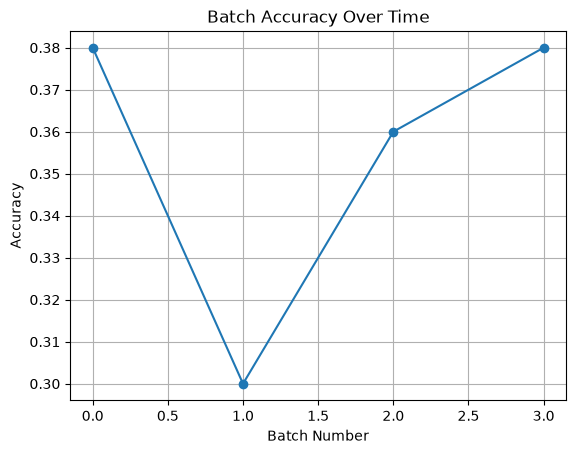

In [33]:
plt.plot(batch_scores, marker="o")
plt.title("Batch Accuracy Over Time")
plt.xlabel("Batch Number")
plt.ylabel("Accuracy")
plt.grid(True)
plt.show()

**Verification against the book:** Figure 13.1 is reproduced exactly: batch accuracies **0.38, 0.30, 0.36, 0.38** ✔. The book comments: "Although there is a dip initially … we'd expect the accuracy to increase over each consecutive batch, which appears to be the case … Although we are only simulating three batches, we can see that the general trend is going up."

> **Book correction (the simulation does not simulate drift, and the reading of the plot is wrong).**
> 1. **Every accuracy is below 0.5** — on a binary problem that is *worse than guessing*. This is not a model "dipping"; it is a model that is systematically wrong.
> 2. The reason: `X_pub` is generated with `random_state=2025`, but `make_classification` draws the *structure of the problem* (informative directions, class separation) from the seed. The "stream" is a **different classification problem**, not a drifted version of the training data. The cells below show that a model trained on it reaches 0.85, while the 2024 model gets 0.355 on it.
> 3. **Nothing is learned between batches** (the loop only calls `predict`; `partial_fit` is called once, afterwards), so the batch-to-batch changes (0.38, 0.30, 0.36, 0.38) are sampling noise on 50 samples each (standard error ≈ 0.07); no trend, no "going up". And there are **four** batches, not three.
> 4. `warm_start=True` has no role in `partial_fit`; and the "retraining" `partial_fit(X_pub, y_pub)` trains on exactly the data it should be *evaluated* on, and the improvement is never measured.

In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

print("2024 model on the whole 2025 'stream'      : accuracy", round(LogisticRegression().fit(X_train, y_train).score(X_pub, y_pub), 3))
print("a model trained ON the 2025 data (5-fold CV): accuracy", round(cross_val_score(LogisticRegression(), X_pub, y_pub, cv=5).mean(), 3), " -> the 2025 data are learnable: it is a different problem")
print("standard error of an accuracy near 0.35 on 50 samples:", round(np.sqrt(0.35 * 0.65 / 50), 3))

clf_updated = SGDClassifier(loss="log_loss", random_state=2024)
clf_updated.partial_fit(X_train, y_train, classes=[0, 1]); before = clf_updated.score(X_pub, y_pub)
clf_updated.partial_fit(X_pub, y_pub)
print(f"book's retraining step: accuracy on the stream before {before:.3f} -> after {clf_updated.score(X_pub, y_pub):.3f} (measured on the data it was just trained on, so it says little)")

2024 model on the whole 2025 'stream'      : accuracy 0.32
a model trained ON the 2025 data (5-fold CV): accuracy 0.845  -> the 2025 data are learnable: it is a different problem
standard error of an accuracy near 0.35 on 50 samples: 0.067
book's retraining step: accuracy on the stream before 0.355 -> after 0.775 (measured on the data it was just trained on, so it says little)


### How it works…
For models with `partial_fit` (such as `SGDClassifier`) training can continue as new data arrive; batch accuracy is "a simple drift detector"; when it falls below a threshold, retrain or update. A *correct* simulation needs (a) a stream that really drifts away from the training distribution, (b) a loop that scores each batch **before** learning from it ("test-then-train", or *prequential* evaluation) and (c) a comparison of update strategies.

**Extension 1 — a stream with real drift.** 12 batches of 200 samples: the true decision boundary *rotates* by 8° per batch (concept drift) and feature 0 shifts to the right (covariate drift). Three strategies are compared: a **static** model trained once; an **online** model that `partial_fit`s each batch after scoring it; and a **threshold-triggered** model that is retrained from scratch on the last two batches whenever a batch scores below 0.85.

,static,online,triggered,KS p (feature 0),"KS p (feature 4, no drift)",retrained after this batch
batch,,,,,,
0,0.895,0.900,0.895,0.489,0.894,
1,0.880,0.870,0.880,0.001,0.068,
2,0.865,0.880,0.865,0.000,0.101,
3,0.900,0.905,0.900,0.000,0.173,
4,0.825,0.905,0.825,0.000,0.551,True
5,0.855,0.945,0.920,0.000,0.551,
6,0.870,0.915,0.900,0.000,0.254,
7,0.815,0.935,0.845,0.000,0.572,True
8,0.830,0.960,0.925,0.000,0.343,


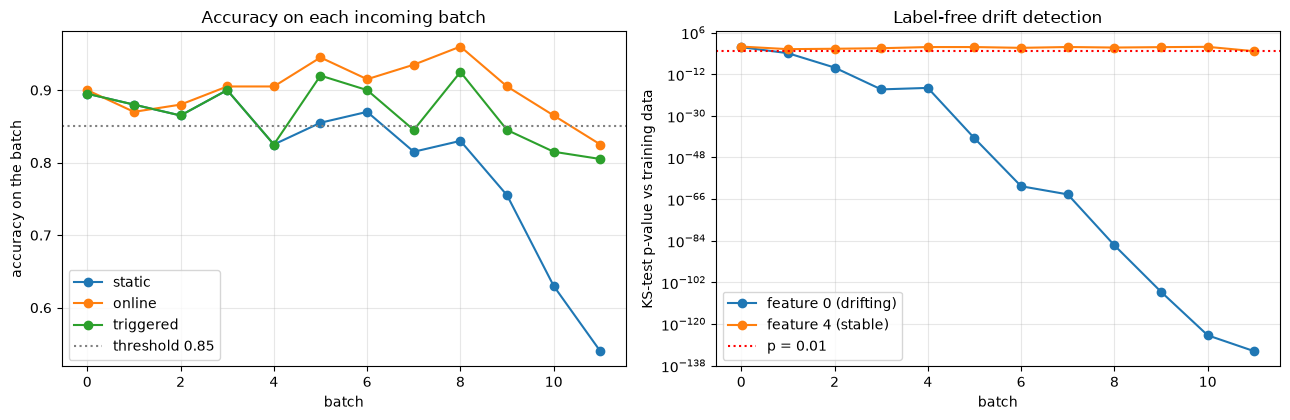

In [35]:
from scipy.stats import ks_2samp
rng = np.random.default_rng(7)
N_FEATURES, BATCH, N_BATCHES, THRESHOLD = 5, 200, 12, 0.85

def make_batch(t, n=BATCH):
    theta = np.deg2rad(8 * t)                                   # the boundary rotates 8 degrees per batch (concept drift)
    Xb = rng.normal(size=(n, N_FEATURES)); Xb[:, 0] += 0.25 * t  # feature 0 drifts to the right (covariate drift)
    return Xb, (np.cos(theta) * Xb[:, 0] + np.sin(theta) * Xb[:, 1] + rng.normal(scale=0.3, size=n) > 0).astype(int)

X_ref, y_ref = make_batch(0, 1000)                                # training data = the distribution at t = 0
static = LogisticRegression().fit(X_ref, y_ref)
online = SGDClassifier(loss="log_loss", alpha=1e-4, random_state=0).fit(X_ref, y_ref)
triggered = LogisticRegression().fit(X_ref, y_ref)
history = [(X_ref[:BATCH], y_ref[:BATCH])]
rows = []
for t in range(N_BATCHES):
    Xb, yb = make_batch(t)
    row = {"batch": t,
           "static": static.score(Xb, yb), "online": online.score(Xb, yb), "triggered": triggered.score(Xb, yb),
           "KS p (feature 0)": ks_2samp(X_ref[:, 0], Xb[:, 0]).pvalue, "KS p (feature 4, no drift)": ks_2samp(X_ref[:, 4], Xb[:, 4]).pvalue}
    online.partial_fit(Xb, yb)                                    # test-then-train
    history.append((Xb, yb))
    if row["triggered"] < THRESHOLD:                              # retrain from scratch on the last two labelled batches
        Xr = np.vstack([h[0] for h in history[-2:]]); yr = np.concatenate([h[1] for h in history[-2:]])
        triggered = LogisticRegression().fit(Xr, yr); row["retrained after this batch"] = True
    rows.append(row)
mon = pd.DataFrame(rows).set_index("batch")
display(mon.round(3).fillna(""))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
for c in ["static", "online", "triggered"]:
    ax[0].plot(mon.index, mon[c], "o-", label=c)
ax[0].axhline(THRESHOLD, color="gray", ls=":", label=f"threshold {THRESHOLD}"); ax[0].set_xlabel("batch"); ax[0].set_ylabel("accuracy on the batch"); ax[0].legend(); ax[0].grid(alpha=0.3); ax[0].set_title("Accuracy on each incoming batch")
ax[1].semilogy(mon.index, mon["KS p (feature 0)"], "o-", label="feature 0 (drifting)"); ax[1].semilogy(mon.index, mon["KS p (feature 4, no drift)"], "o-", label="feature 4 (stable)")
ax[1].axhline(0.01, color="red", ls=":", label="p = 0.01"); ax[1].set_xlabel("batch"); ax[1].set_ylabel("KS-test p-value vs training data"); ax[1].legend(); ax[1].grid(alpha=0.3); ax[1].set_title("Label-free drift detection")
plt.tight_layout(); plt.show()

* The **static model decays** from 0.895 to 0.54 (essentially chance) as the boundary rotates; it first falls below the 0.85 threshold at batch 4 (0.825).
* The **online model** (`partial_fit` after each batch) adapts and never drops below 0.825 (0.865–0.96 for most batches).
* The **threshold-triggered model** is retrained five times (batches 4, 7, 9, 10, 11) and stays between 0.805 and 0.925: retraining on the last two batches always lags a continuously moving boundary, so the threshold keeps being crossed.
* The **KS test** on the drifting feature raises an alarm (p ≈ 0.001) already at **batch 1** — three batches before the static model's accuracy falls below the threshold — and needs no labels. But a drift alarm is not proof of performance loss: accuracy at batches 1–3 is still 0.865–0.90, because covariate drift alone does not make the old boundary wrong; and the stable control feature still dips to p = 0.009 at batch 11 — with many features and many batches, occasional false alarms are expected.

Lessons: monitor inputs *and* outcomes; set thresholds knowing the noise (200 samples → standard error ≈ 0.025); choose the update policy for the kind of drift (online adaptation for gradual drift, trigger-based retraining for abrupt change).

### There's more…
The book mentions more sophisticated detectors: distribution statistics, KL divergence on embeddings, statistical tests, and automated retraining with alerting and rollback. The Kolmogorov–Smirnov test above is the simplest such test and needs **no labels** — important, because in production the true labels often arrive late or never, so accuracy cannot be monitored directly.

### Theory — monitoring
* **Covariate drift** ($P(x)$ changes), **concept drift** ($P(y\mid x)$ changes), **label/prior drift** ($P(y)$ changes). Input tests (KS, PSI, χ²) catch the first; only labelled outcomes (accuracy, calibration) reveal concept drift.
* **What to monitor:** input feature distributions, prediction distribution (e.g. share of positives), data quality (missing values, ranges), latency, and — when labels arrive — performance metrics with confidence intervals (a batch of 50 samples has a standard error of ±0.07!).
* **Update strategies:** periodic retraining; trigger-based retraining; online learning (`partial_fit`); always against a validation protocol and with rollback. Online updates adapt quickly but can also learn from corrupted data.
* **Evaluate prequentially:** score a batch with the *current* model, only then learn from it.

### Hands-on workflow (book)
Use an incremental model trained on historical data, feed validation batches over time, track and visualise batch performance and automate retraining when accuracy falls below a threshold — as in Extension 1 (Exercise 2 repeats it with a sudden shift).

## 5. Managing the model life cycle

**Summary.** Models are never "set it and forget it": they degrade as data and targets change. Managing the life cycle means **versioning**, **reproducibility** (record how the model was made), **document control** and **consistency** between training and serving environments.

### Getting ready

In [36]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score
from joblib import dump
import json

In [37]:
X, y = make_classification(
    n_samples=800, n_features=20, random_state=2024)
clf = RandomForestClassifier(
    n_estimators=50, random_state=2024)
clf.fit(X, y)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",50
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",2024
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootst

### How to do it…
**1. Save the versioned artifact; 2. save metadata about the environment; 3. capture a validation snapshot:**

In [38]:
version = "v1.0"
dump(clf, f"rf_{version}.joblib")

['rf_v1.0.joblib']

In [39]:
meta = {"version": version,"sklearn": "1.3.2",
        "numpy": str(np.__version__)}
with open(f"rf_{version}_metadata.json", "w") as f:
    json.dump(meta, f)
print(meta)
print("... but the library actually in use is scikit-learn", sklearn.__version__)

{'version': 'v1.0', 'sklearn': '1.3.2', 'numpy': '2.5.3'}
... but the library actually in use is scikit-learn 1.9.1


In [40]:
try:
    Xv, yv = load_iris(return_X_y=True)
    yv_pred = clf.predict(Xv)
    val_acc = accuracy_score(yv, yv_pred)
    with open(f"rf_{version}_val.txt", "w") as f:
        f.write(f"{val_acc:.4f}")
except ValueError as e:
    print("The book's step 3 fails:", type(e).__name__ + ":", e)

The book's step 3 fails: ValueError: X has 4 features, but RandomForestClassifier is expecting 20 features as input.


> **Book correction (the validation snapshot cannot work).** Step 3 validates the 20-feature forest on the **Iris** dataset (4 features, 3 classes, an unrelated problem), which raises `ValueError: X has 4 features, but RandomForestClassifier is expecting 20 features`. Even if the shapes matched, an "accuracy" on an unrelated dataset is meaningless.
> The metadata hard-codes `"sklearn": "1.3.2"` instead of `sklearn.__version__` — the record is wrong as soon as the library is upgraded (here the library is 1.9.1). And the book's own text says to snapshot "a small validation set **with its predicted outputs**", but the code would save only one accuracy number: a number cannot tell you *what changed* after an upgrade; predictions can.

### How it works…
The book (citing the scikit-learn roadmap): snapshot the model, the code, the library versions and a small validation set with its predicted outputs, so the model can be validated after future upgrades or ports; metadata helps trace issues, roll back and reproduce. A working version of this recipe:

**Extension — a proper artifact: model + metadata + checksum + validation snapshot,** and a function that verifies an artifact (for example after an upgrade):

In [41]:
import platform, datetime, hashlib
from pathlib import Path
from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=2024)
model_v1 = RandomForestClassifier(n_estimators=50, random_state=2024).fit(X_tr, y_tr)

def save_artifact(model, version, X_val, y_val, n_snapshot=50):
    path = Path(f"rf_{version}.joblib"); dump(model, path)
    np.savez(f"rf_{version}_val.npz", X=X_val[:n_snapshot], pred=model.predict(X_val[:n_snapshot]), proba=model.predict_proba(X_val[:n_snapshot]))
    meta = {"version": version, "sklearn": sklearn.__version__, "numpy": np.__version__, "python": platform.python_version(),
            "created_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
            "n_features": int(model.n_features_in_), "params": model.get_params(),
            "validation_accuracy": round(float(accuracy_score(y_val, model.predict(X_val))), 4),
            "sha256": hashlib.sha256(path.read_bytes()).hexdigest()}
    Path(f"rf_{version}_metadata.json").write_text(json.dumps(meta, indent=2))
    return meta

def verify_artifact(version):
    meta = json.loads(Path(f"rf_{version}_metadata.json").read_text()); problems = []
    if hashlib.sha256(Path(f"rf_{version}.joblib").read_bytes()).hexdigest() != meta["sha256"]:
        return ["checksum mismatch: the file is corrupted or was modified (not loaded)"]
    if meta["sklearn"] != sklearn.__version__:
        problems.append(f"trained with scikit-learn {meta['sklearn']}, running {sklearn.__version__}")
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always"); model = load_model(f"rf_{version}.joblib")
    problems += [w.category.__name__ for w in caught][:1]
    snap = np.load(f"rf_{version}_val.npz")
    if not np.array_equal(model.predict(snap["X"]), snap["pred"]): problems.append("predictions differ from the snapshot")
    elif not np.allclose(model.predict_proba(snap["X"]), snap["proba"], atol=1e-8): problems.append("probabilities differ from the snapshot")
    return problems

from joblib import load as load_model
meta_v1 = save_artifact(model_v1, "v1.0", X_val, y_val)
print(json.dumps({k: meta_v1[k] for k in ["version", "sklearn", "numpy", "python", "n_features", "validation_accuracy", "sha256"]}, indent=2))
print("verify v1.0:", verify_artifact("v1.0") or "OK: checksum, version and snapshot predictions all match")

{
  "version": "v1.0",
  "sklearn": "1.9.1",
  "numpy": "2.5.3",
  "python": "3.14.7",
  "n_features": 20,
  "validation_accuracy": 0.9563,
  "sha256": "c75d0e55b5e29a15d1538d4072c8bad6a30a47edf4bbc616409cb2557b614301"
}


verify v1.0: OK: checksum, version and snapshot predictions all match


Now three failures that the verification must catch — a library upgrade (simulated as before), a corrupted file, and a rollback to the last good version:

In [42]:
def simulate_old_version(fn, fake="1.3.2"):               # a simulation: only the installed scikit-learn can really be run
    real_base, real_top = sklearn.base.__version__, sklearn.__version__
    sklearn.base.__version__ = sklearn.__version__ = fake
    try:
        return fn()
    finally:
        sklearn.base.__version__, sklearn.__version__ = real_base, real_top

# v1.1: "trained with scikit-learn 1.3.2" (simulated), a larger forest
model_v11 = RandomForestClassifier(n_estimators=100, random_state=2024).fit(X_tr, y_tr)
simulate_old_version(lambda: save_artifact(model_v11, "v1.1", X_val, y_val))

# v1.2: file corrupted after saving
model_v12 = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=2024).fit(X_tr, y_tr)
save_artifact(model_v12, "v1.2", X_val, y_val)
raw = bytearray(Path("rf_v1.2.joblib").read_bytes()); raw[len(raw) // 2] ^= 0xFF; Path("rf_v1.2.joblib").write_bytes(bytes(raw))

for v in ["v1.0", "v1.1", "v1.2"]:
    print(f"verify {v}:", verify_artifact(v) or "OK")

registry = ["v1.0", "v1.1", "v1.2"]                      # oldest -> newest
good = [v for v in reversed(registry) if not verify_artifact(v)]
print("\nrollback: newest version that passes every check ->", good[0] if good else None)

verify v1.0: OK
verify v1.1: ['trained with scikit-learn 1.3.2, running 1.9.1', 'InconsistentVersionWarning']
verify v1.2: ['checksum mismatch: the file is corrupted or was modified (not loaded)']

rollback: newest version that passes every check -> v1.0


The verification catches three different failures: **v1.0** passes (checksum, version and snapshot predictions match); **v1.1** (the simulated old-version artifact) is flagged by the version check and an `InconsistentVersionWarning` even though its predictions happen to match the snapshot; **v1.2** fails the checksum after a single flipped byte and is not even unpickled; the rollback logic selects **v1.0**. A lone accuracy number, as in the book, could have detected none of these.

### There's more…
Model registries such as **MLflow** and **BentoML** automate artifact storage, metadata tracking and rollback; the book stresses that snapshotting dependencies and validation outputs remains good practice even with such tools.

### Theory — the life cycle of a model
* **Version everything:** model, code, training data (or a hash/ID), library versions, hyper-parameters, random seeds, metrics — enough to rebuild or audit any deployed prediction.
* **Validate artifacts, not just models:** a checksum (integrity), version check (compatibility), and a *golden snapshot* — fixed inputs with recorded outputs — compared after every upgrade or port.
* **Promote through stages** (development → staging → production) with a registry; keep the previous version for **rollback**.
* **Retire models:** schedule reviews, since "all models deteriorate".

### Hands-on workflow (book)
Train a model and assign a semantic version, save the model, metadata and validation snapshot, simulate a library upgrade, attempt to load the artifact and validate predictions, record and compare the results — as above.

## 6. Setting up deployment pipelines

**Summary.** Reliable deployment needs automation: serialise the model, run validation checks, and promote only if they pass — a CI/CD(/CT) pipeline. In scikit-learn a `Pipeline` bundles preprocessing and the classifier into one artifact that is validated and served as a unit.

### Getting ready

In [43]:
import numpy as np
from sklearn.datasets import make_classification
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from joblib import dump, load
from sklearn.metrics import accuracy_score

In [44]:
X, y = make_classification(
    n_samples=500, n_features=10, random_state=2024)
pipe = Pipeline([
    ("scale", StandardScaler()),
    ("clf", LogisticRegression())
])
pipe.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


### How to do it…
**1. Export the pipeline; 2. load it in the deployment environment; 3. "simulate CI": validate accuracy; 4. deploy only above a threshold.** (The book's validation data are unseeded noise; a seed is added so the cell is reproducible.)

In [45]:
dump(pipe, "pipeline.joblib")

['pipeline.joblib']

In [46]:
prod_pipe = load("pipeline.joblib")

In [47]:
np.random.seed(2024)                      # added for reproducibility
Xt, yt = (
    np.random.rand(100, 10),
    np.random.randint(0, 2, 100)
)
acc = accuracy_score(yt, prod_pipe.predict(Xt))
print("Validation accuracy:", acc)

Validation accuracy: 0.52


In [48]:
if acc > 0.8:
    print("Auto-deploy allowed")
else:
    print("Halt deployment and review")

Halt deployment and review


**Verification against the book:** the code runs and — as it must — halts the deployment ✔. The book does not print the output and says the threshold is "arbitrary".

> **Book correction (this CI check can never pass, so it tests nothing).** `Xt` is uniform noise and `yt` are **random labels** unrelated to `Xt`: *no* model can score above chance on them. The gate is therefore always closed, whatever the model quality:

In [49]:
best = 0
accs = []
for seed in range(200):
    r = np.random.RandomState(seed)
    accs.append(accuracy_score(r.randint(0, 2, 100), prod_pipe.predict(r.rand(100, 10))))
print(f"accuracy of the trained pipeline on 200 random validation sets: mean {np.mean(accs):.3f}, max {np.max(accs):.2f}, sets above the 0.8 threshold: {sum(a > 0.8 for a in accs)}")
print(f"(on its own training data it scores {pipe.score(X, y):.3f})")

accuracy of the trained pipeline on 200 random validation sets: mean 0.504, max 0.62, sets above the 0.8 threshold: 0
(on its own training data it scores 0.908)


Further issues: the model is fitted on *all* the data, leaving no honest hold-out set; the text says "let's add a conditional at the end of our pipeline", but the `if` is plain Python *outside* the `Pipeline` object; and a single accuracy threshold is the only check.

### How it works…
Using `Pipeline` ties preprocessing and prediction into **one artifact** that can be validated as a unit and reused identically across environments; a CI step can score the artifact on a validation/canary set and promote it only if it meets the thresholds. The `Pipeline` point is easy to demonstrate — *training–serving skew*: features on different scales, scaler saved separately from (or forgotten by) the classifier:

In [50]:
from sklearn.model_selection import train_test_split

scales = np.logspace(0, 3, 10)                                             # features in very different units (1 ... 1000)
Xs = X * scales
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, y, test_size=0.3, random_state=2024)

full = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression())]).fit(Xs_tr, ys_tr)
scaler = StandardScaler().fit(Xs_tr); clf_only = LogisticRegression().fit(scaler.transform(Xs_tr), ys_tr)        # trained on scaled data...
print("whole Pipeline served on raw inputs      : accuracy", round(full.score(Xs_te, ys_te), 3))
print("classifier alone served on raw inputs    : accuracy", round(clf_only.score(Xs_te, ys_te), 3), "  <- the scaler was not shipped with it")
print("classifier + scaler applied by hand      : accuracy", round(clf_only.score(scaler.transform(Xs_te), ys_te), 3))

whole Pipeline served on raw inputs      : accuracy 0.873
classifier alone served on raw inputs    : accuracy 0.58   <- the scaler was not shipped with it
classifier + scaler applied by hand      : accuracy 0.873


The whole `Pipeline` works on raw inputs (accuracy 0.873). The classifier alone — trained on scaled data and deployed *without its scaler* — drops to **0.58**, close to chance; applying the scaler by hand restores 0.873. Shipping the preprocessing inside the artifact removes this class of *training–serving skew*.

**Extension — a deployment gate that actually protects production.** A gate should validate the **artifact** on a *held-out validation set from the same distribution*, with several independent checks: schema, minimum quality, **no regression versus the current production model (the "champion")**, a latency budget and deterministic output. Three candidates are judged against a champion:

In [51]:
from time import perf_counter
from sklearn.utils import resample

X_all, y_all = make_classification(n_samples=2000, n_features=10, random_state=2024)
X_tr, X_hold, y_tr, y_hold = train_test_split(X_all, y_all, test_size=0.25, random_state=2024)

def deployment_gate(path, X_val, y_val, expected_features, min_accuracy=0.85, champion_accuracy=None, max_regression=0.01, max_latency_ms=50):
    model = load(path); checks = {}
    checks["schema_ok"] = getattr(model, "n_features_in_", None) == expected_features
    if not checks["schema_ok"]:
        return False, checks
    acc = accuracy_score(y_val, model.predict(X_val)); checks["accuracy"] = round(acc, 4)
    checks["accuracy_ok"] = acc >= min_accuracy
    if champion_accuracy is not None:
        checks["no_regression_ok"] = acc >= champion_accuracy - max_regression
    t0 = perf_counter(); model.predict(X_val[:1]); latency = (perf_counter() - t0) * 1000
    checks["latency_ms"] = round(latency, 2); checks["latency_ok"] = latency <= max_latency_ms
    checks["deterministic_ok"] = np.array_equal(model.predict(X_val), model.predict(X_val))
    return all(v for k, v in checks.items() if k.endswith("_ok")), checks

champion = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression())]).fit(X_tr, y_tr); dump(champion, "champion.joblib")
champ_acc = accuracy_score(y_hold, champion.predict(X_hold))
rng_l = np.random.default_rng(0)
candidates = {
    "A: same pipeline, retrained on a bootstrap resample": Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression())]).fit(*resample(X_tr, y_tr, random_state=1)),
    "B: trained on shuffled labels (bug)":       Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression())]).fit(X_tr, rng_l.permutation(y_tr)),
    "C: underfitted (C = 1e-6)":                 Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(C=1e-6))]).fit(X_tr, y_tr),
    "D: wrong feature set (8 of 10 columns)":    Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression())]).fit(X_tr[:, :8], y_tr),
}
rows = {}
for name, cand in candidates.items():
    dump(cand, "candidate.joblib")
    ok, checks = deployment_gate("candidate.joblib", X_hold, y_hold, expected_features=10, champion_accuracy=champ_acc)
    rows[name] = {"decision": "DEPLOY" if ok else "HALT", **checks}
print(f"champion (production) accuracy on the held-out set: {champ_acc:.3f}")
display(pd.DataFrame(rows).T)

champion (production) accuracy on the held-out set: 0.866


,decision,schema_ok,accuracy,accuracy_ok,no_regression_ok,latency_ms,latency_ok,deterministic_ok
"A: same pipeline, retrained on a bootstrap resample",DEPLOY,True,0.868,True,True,0.72,True,True
B: trained on shuffled labels (bug),HALT,True,0.466,False,False,0.56,True,True
C: underfitted (C = 1e-6),HALT,True,0.48,False,False,0.84,True,True
D: wrong feature set (8 of 10 columns),HALT,False,NaN,NaN,NaN,NaN,NaN,NaN


The gate halts three of the four candidates, each for a different reason: **B** (shuffled labels) and **C** (under-fitted) fail the accuracy and no-regression checks (0.47 and 0.48 against the champion's 0.866); **D** (trained on 8 features) is stopped by the schema check *before* it can fail in production; **A** (a retrained equivalent, 0.868 vs 0.866) passes every check and is deployed. That is the value of testing several independent properties. The book's gate would have stopped **all four** — and any good model too.

### There's more…
CI/CD/CT workflows can be built with GitHub Actions, CircleCI or similar tools, triggering retraining, serialisation, validation and deployment to cloud endpoints; containerising the pipeline with Docker and versioning artifacts adds reliability.

### Theory — deployment pipelines
* **One artifact:** put *every* data-dependent transformation in the `Pipeline` (scaling, encoding, imputation, feature selection) so training and serving cannot diverge.
* **Gate on evidence:** held-out data from the *production* distribution, several metrics (not only accuracy), non-regression against the champion, behavioural tests (schema, determinism, latency), a **canary**/shadow deployment before full rollout, and a rollback path.
* **Thresholds are business decisions** (costs of false positives/negatives, ROI), as the book stresses; the code only enforces them.
* **Continuous training (CT):** monitoring (Section 4) triggers retraining; retrained candidates go through the same gate.

### Hands-on workflow (book)
Create a preprocessing + model pipeline, save and load it as a single artifact, validate performance in simulated CI logic and enforce deployment gating based on thresholds — as above.

## 7. Practical exercises in model deployment

The book lists three exercises with implementation steps only (no code). They are implemented here (Breast Cancer data for 1 and 3).

### Exercise 1: Saving and reloading a model pipeline for deployment
Steps (book): load the libraries, create and train the pipeline, save and reload it, generate new predictions.

In [52]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from joblib import dump, load

Xb, yb = load_breast_cancer(return_X_y=True)
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.25, stratify=yb, random_state=2024)

pipe_b = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xb_tr, yb_tr)
dump(pipe_b, "breast_cancer_pipeline.joblib")
reloaded = load("breast_cancer_pipeline.joblib")                                  # "the production environment"

new_patients = Xb_te[:5]
print("predictions   :", reloaded.predict(new_patients), "| true labels:", yb_te[:5])
print("P(benign)     :", reloaded.predict_proba(new_patients)[:, 1].round(3))
print("identical to the original pipeline:", np.array_equal(pipe_b.predict_proba(Xb_te), reloaded.predict_proba(Xb_te)), "| test accuracy:", round(reloaded.score(Xb_te, yb_te), 3))
print("artifact:", os.path.getsize("breast_cancer_pipeline.joblib"), "bytes | steps:", [n for n, _ in reloaded.steps], "| expects", reloaded.n_features_in_, "features")

predictions   : [0 1 1 0 0] | true labels: [0 1 1 0 0]
P(benign)     : [0.    1.    0.998 0.    0.   ]
identical to the original pipeline: True | test accuracy: 0.972
artifact: 2305 bytes | steps: ['standardscaler', 'logisticregression'] | expects 30 features


The reloaded pipeline reproduces the original probabilities exactly, accepts *raw* (unscaled) features because the scaler is inside the artifact, and weighs 2.3 kB; test accuracy 0.972.

### Exercise 2: Monitoring model accuracy over time
Steps (book): load the libraries, simulate the streaming setup, train and evaluate incrementally, plot batch accuracy. A stream with a **sudden** shift at batch 6 (the label rule changes), a monitored accuracy threshold and an automatic retraining trigger:

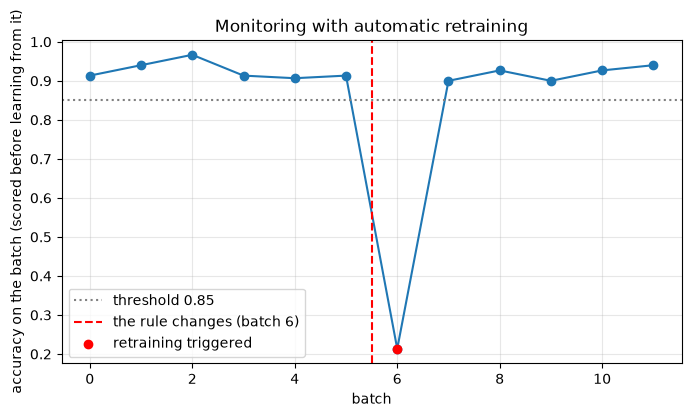

accuracy per batch: [0.91 0.94 0.97 0.91 0.91 0.91 0.21 0.9  0.93 0.9  0.93 0.94]
retraining triggered at batches: [6]


In [53]:
rng2 = np.random.default_rng(11)
def stream_batch(t, n=150):
    Xb_ = rng2.normal(size=(n, 4))
    w = np.array([1.5, -1.0, 0.0, 0.0]) if t < 6 else np.array([-1.0, 1.5, 1.0, 0.0])       # the true rule changes at batch 6
    return Xb_, (Xb_ @ w + rng2.normal(scale=0.4, size=n) > 0).astype(int)

X0, y0 = stream_batch(0, 800)
model = SGDClassifier(loss="log_loss", alpha=1e-4, random_state=0).fit(X0, y0)
accs, retrain_at, THR = [], [], 0.85
for t in range(12):
    Xb_, yb_ = stream_batch(t)
    a = model.score(Xb_, yb_); accs.append(a)                       # score first ...
    if a < THR:
        retrain_at.append(t)
        for _ in range(5):                                          # ... then adapt: a few passes over the (labelled) batch
            model.partial_fit(Xb_, yb_)
    else:
        model.partial_fit(Xb_, yb_)

plt.figure(figsize=(8, 4.2))
plt.plot(range(12), accs, "o-"); plt.axhline(THR, color="gray", ls=":", label=f"threshold {THR}")
plt.axvline(5.5, color="red", ls="--", label="the rule changes (batch 6)")
plt.scatter(retrain_at, [accs[t] for t in retrain_at], c="red", zorder=3, label="retraining triggered")
plt.xlabel("batch"); plt.ylabel("accuracy on the batch (scored before learning from it)"); plt.legend(); plt.grid(alpha=0.3); plt.title("Monitoring with automatic retraining"); plt.show()
print("accuracy per batch:", np.round(accs, 2)); print("retraining triggered at batches:", retrain_at)

Accuracy is 0.91–0.97 until the rule changes; at batch 6 it collapses to **0.21** — far below chance, because the model now confidently predicts the *opposite* of the new rule — the threshold fires, and the retraining (five passes over that batch) restores 0.90–0.94 from batch 7 on. One caveat: the adaptation uses the labelled batch that triggered the alarm, so labels must arrive quickly; with delayed labels, the damage lasts correspondingly longer.

### Exercise 3: Automating deployment checks using validation thresholds
Steps (book): load the libraries, train and export the model, load and validate with test data, conditionally approve the deployment — using the multi-check gate of Section 6 on the Breast Cancer data.

In [54]:
champion_b = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xb_tr, yb_tr); dump(champion_b, "champion_b.joblib")
champ_acc_b = champion_b.score(Xb_te, yb_te)

cands = {"retrained with more regularisation (C=0.1)": make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=1000)).fit(Xb_tr, yb_tr),
         "without scaling (raw features)":            LogisticRegression(max_iter=5000).fit(Xb_tr, yb_tr),
         "trained on only 20 patients":               make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xb_tr[:20], yb_tr[:20])}
rows = {}
for name, cand in cands.items():
    dump(cand, "candidate_b.joblib")
    ok, checks = deployment_gate("candidate_b.joblib", Xb_te, yb_te, expected_features=30, min_accuracy=0.95, champion_accuracy=champ_acc_b, max_regression=0.01)
    rows[name] = {"decision": "DEPLOY" if ok else "HALT", **checks}
print(f"champion accuracy on the held-out set: {champ_acc_b:.3f} | minimum required: 0.95 | allowed regression: 0.01")
display(pd.DataFrame(rows).T)

champion accuracy on the held-out set: 0.972 | minimum required: 0.95 | allowed regression: 0.01


,decision,schema_ok,accuracy,accuracy_ok,no_regression_ok,latency_ms,latency_ok,deterministic_ok
retrained with more regularisation (C=0.1),DEPLOY,True,0.972,True,True,0.56,True,True
without scaling (raw features),HALT,True,0.958,True,False,0.27,True,True
trained on only 20 patients,DEPLOY,True,0.965,True,True,0.53,True,True


Champion 0.972 on 143 held-out patients; minimum 0.95; allowed regression 0.01. The retrained C = 0.1 model (0.972) is deployed. The unscaled model (0.958) passes the minimum but is **halted by the no-regression check** (0.958 < 0.962), a difference of 2 patients; the model trained on only 20 patients (0.965) is **deployed** (0.965 ≥ 0.962), a difference of 1 patient. Both decisions lie within the noise: the standard error of an accuracy near 0.97 on 143 samples is 0.014, larger than the 0.01 tolerance — the gate is flipping on noise. A good gate uses a tolerance above the standard error, a larger validation set or a paired test (McNemar), and should also catch a 20-patient model by other checks (e.g. a minimum training-set size recorded in the metadata).

## Chapter takeaways
1. **Deployment = artifact + serving + monitoring.** A saved model reproduces predictions, probabilities and parameters exactly; serving needs input validation (the model rejects a wrong width); and **batch prediction is ≈ 700× cheaper per sample** than one-by-one calls.
2. **`joblib` vs `pickle`:** same size and speed on a 20 MB forest — `joblib`'s real advantages are compression (4.6 MB) and memory-mapping. **Unpickling executes code** (demonstrated), and a version mismatch triggers `InconsistentVersionWarning`: store the library versions and a SHA-256 next to every artifact.
3. **`n_jobs` is a trade-off:** single-row prediction was ≈ 3× *slower* with threads (12 → 36–39 ms), 100,000-row batches 4× faster, fitting 4× faster, cross-validation 1.8× faster. The book's batch-latency cell with `n_jobs=-1` is slower than `n_jobs=1`.
4. **The book's monitoring simulation is not a simulation of drift:** its "stream" is a different classification problem (batch accuracies 0.30–0.38 < chance), nothing is learned between batches, and the "upward trend" is noise (SE ≈ 0.07). With real drift the static model decayed from 0.90 to 0.54, an online model stayed ≥ 0.825, and a label-free KS test flagged the drift three batches before accuracy crossed the threshold.
5. **Life cycle:** the book's validation snapshot crashes (Iris through a 20-feature model) and hard-codes a wrong library version. A working artifact has metadata, a checksum and a golden snapshot of predictions — which caught a version mismatch and a corrupted file and drove a rollback.
6. **Pipelines and gates:** one `Pipeline` artifact prevents training–serving skew (0.873 vs 0.58); the book's CI check on random noise can never pass (maximum 0.62 over 200 sets); a multi-check gate (schema, quality, regression, latency, determinism) halted three bad candidates and approved the good one — but thresholds must exceed the noise of the validation set (SE 0.014 on 143 samples).
7. **Beyond the book:** model registries (MLflow, BentoML), containers, CI/CD services, safer formats (skops, ONNX) and full MLOps are the next steps.

### Book corrections noted in this notebook
| Where | Book says / does | Actually |
|---|---|---|
| Overview recipe | "using Python's **built-in** functions" | `joblib` is a third-party package (a scikit-learn dependency) |
| `joblib` vs `pickle` | pickle "can struggle with large NumPy arrays" | with Python ≥ 3.8 pickle is as small and fast (20.5 MB each); `joblib`'s real edge is compression and `mmap_mode` |
| Serialization recipe | "convert our models into Python arrays" | serialisation produces a *byte stream* (as the book says later) |
| Scaling recipe | "predicting on a random batch size of text data" | the batch is numeric noise, not text |
| Scaling recipe | implicit advice: `n_jobs=-1` | 3× *slower* for single rows and 1,000-row batches; faster only for large batches (100,000 rows: 4×) and for fitting |
| Monitoring recipe | accuracy "dips" then increases "over each consecutive batch" | all batches are 0.30–0.38 (below chance); no learning between batches; the change is noise (SE ≈ 0.07) |
| Monitoring data | `X_pub` as "streaming/drifted" data | `random_state=2025` creates a *different* classification problem; a model trained on it reaches 0.85 |
| Monitoring text | "we are only simulating three batches" | there are four batches |
| Monitoring code | `SGDClassifier(..., warm_start=True)` | `warm_start` is irrelevant to `partial_fit`; the retraining step uses the same data it is meant to be evaluated on, and its effect is never measured |
| Life-cycle recipe | validation snapshot on `load_iris` | `ValueError`: 4 features vs a 20-feature model; an accuracy on an unrelated dataset means nothing |
| Life-cycle recipe | metadata `"sklearn": "1.3.2"` | hard-coded; should be `sklearn.__version__` (1.9.1 here); also only an accuracy is saved though the text says "predicted outputs" |
| Pipeline recipe | CI check on `np.random.rand` features and random labels | any model scores ≈ 0.5 (max 0.62 in 200 trials): the gate can never open |
| Pipeline recipe | "add a conditional at the end of our pipeline" | the `if` is plain Python outside the `Pipeline`; the model is fitted on all data (no hold-out) and a single metric is checked |

*All thirteen chapters are complete.*